<a href="https://colab.research.google.com/github/sergfdz/toronto-crime-classification/blob/main/crime_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SCS_3253_092 Machine Learning**
# **Final Project - Sergio Fernandez**

# DATA DESCRIPTION

The dataset is obtained from the Toronto Police Service Open Data portal.
It contains crime rates across 158 neighbourhoods and 222 features representing
different crime categories and temporal patterns.

# OBJECTIVE
To analyze and classify neighbourhoods into different crime rate levels.

# DATA SOURCE:
Toronto Police Service Open Data

# APPROACH:
- Data exploration and visualization
- Data cleaning and preparation
- Feature engineering
- Model training (Logistic Regression & Random Forest)
- Hyperparameter tuning
- Evaluation and interpretation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Load dataset from local file (included in project folder)
url = "https://raw.githubusercontent.com/sergfdz/toronto-crime-classification/main/crime_data.csv"
df = pd.read_csv(url)

# Show first rows
df.head()

,OBJECTID_1,NEIGHBOURHOOD_NAME,HOOD_158,ASSAULT_2014,ASSAULT_2015,ASSAULT_2016,ASSAULT_2017,ASSAULT_2018,ASSAULT_2019,ASSAULT_2020,...,THEFTOVER_RATE_2019,THEFTOVER_RATE_2020,THEFTOVER_RATE_2021,THEFTOVER_RATE_2022,THEFTOVER_RATE_2023,THEFTOVER_RATE_2024,THEFTOVER_RATE_2025,POPULATION_2025,Shape__Area,Shape__Length
0,1,South Eglinton-Davisville,174,55,56,66,73,74,62,74,...,13.097577,16.740604,24.216984,11.665436,29.499613,21.188684,20.759809,28902,9.443090e+05,4005.549887
1,2,North Toronto,173,53,57,47,61,66,84,80,...,26.750484,43.862396,11.872959,22.540291,36.945164,30.007502,24.293072,20582,4.020308e+05,2543.945884
2,3,Dovercourt Village,172,62,65,92,105,106,113,91,...,29.775198,22.602276,15.283509,30.555344,22.610792,52.426601,22.850180,13129,1.503002e+06,4965.496448
3,4,Junction-Wallace Emerson,171,164,159,171,161,163,186,171,...,15.985932,36.070698,32.293224,31.383625,33.834587,47.279606,32.400906,27777,2.222867e+06,7435.192384
4,5,Yonge-Bay Corridor,170,387,521,481,602,576,660,377,...,478.723419,258.569733,187.630798,351.821198,337.443207,296.040466,210.071426,16661,1.118725e+06,4811.107669


In [ ]:
import os
os.listdir()

['.config', 'crime_data.csv', 'drive', 'sample_data']

### Understanding data:

In [ ]:
print("Dataset shape:", df.shape)

df.info()

df.describe()

Dataset shape: (158, 222)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Columns: 222 entries, OBJECTID_1 to Shape__Length
dtypes: float64(110), int64(111), object(1)
memory usage: 274.2+ KB


,OBJECTID_1,HOOD_158,ASSAULT_2014,ASSAULT_2015,ASSAULT_2016,ASSAULT_2017,ASSAULT_2018,ASSAULT_2019,ASSAULT_2020,ASSAULT_2021,...,THEFTOVER_RATE_2019,THEFTOVER_RATE_2020,THEFTOVER_RATE_2021,THEFTOVER_RATE_2022,THEFTOVER_RATE_2023,THEFTOVER_RATE_2024,THEFTOVER_RATE_2025,POPULATION_2025,Shape__Area,Shape__Length
count,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,...,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,1.580000e+02,158.000000
mean,79.500000,88.107595,104.525316,113.025316,117.772152,119.658228,123.835443,130.259494,113.677215,120.253165,...,45.728585,40.474752,33.904204,46.094881,52.337241,54.339207,56.830650,20346.341772,4.067004e+06,9587.160127
std,45.754781,51.236381,78.527021,88.443364,92.713991,98.017792,104.886342,108.919077,96.357830,99.084275,...,48.411501,33.551471,33.238793,42.205193,49.421953,45.554522,43.388680,7523.898031,3.864570e+06,4985.192743
min,1.000000,1.000000,15.000000,11.000000,10.000000,20.000000,12.000000,14.000000,10.000000,16.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,4.168056,6.022283,8089.000000,4.020308e+05,2543.945884
25%,40.250000,43.250000,53.500000,55.250000,56.500000,58.000000,59.500000,68.000000,54.500000,56.000000,...,20.299271,20.273739,15.296106,23.501390,23.585889,28.133784,29.193746,14083.250000,1.758514e+06,6296.711355
50%,79.500000,88.500000,82.500000,91.500000,88.500000,94.500000,92.500000,96.000000,86.000000,93.500000,...,35.298006,33.615341,25.876214,37.928200,40.229668,44.536879,46.134712,19041.000000,3.138953e+06,8464.599649
75%,118.750000,133.750000,129.250000,136.000000,137.000000,146.250000,140.500000,156.500000,133.500000,141.750000,...,55.065013,50.010351,39.826097,53.627618,59.632324,66.065889,69.588757,25717.000000,5.168302e+06,11589.882243
max,158.000000,174.000000,416.000000,521.000000,524.000000,602.000000,576.000000,660.000000,751.000000,625.000000,...,478.723419,258.569733,226.120865,351.821198,337.443207,296.040466,274.738281,44636.000000,3.014534e+07,42678.150446


### Data exploration:

In [ ]:
# Ajusta este nombre según tu dataset
neighbourhood_col = 'NEIGHBOURHOOD_NAME'

# Select rate features
rate_cols = [col for col in df.columns if "RATE_2023" in col]

# Keep neighbourhood + rates
df_rates = df[[neighbourhood_col] + rate_cols].copy()

df_rates.head()

,NEIGHBOURHOOD_NAME,ASSAULT_RATE_2023,AUTOTHEFT_RATE_2023,BIKETHEFT_RATE_2023,BREAKENTER_RATE_2023,HOMICIDE_RATE_2023,ROBBERY_RATE_2023,SHOOTING_RATE_2023,THEFTFROMMV_RATE_2023,THEFTOVER_RATE_2023
0,South Eglinton-Davisville,368.745148,73.749031,136.435715,158.560425,0.000000,11.062355,0.000000,147.498062,29.499613
1,North Toronto,554.177429,105.557610,116.113365,163.614288,0.000000,73.890327,0.000000,211.115219,36.945164
2,Dovercourt Village,783.840820,218.570999,286.403381,346.698822,0.000000,158.275543,7.536931,188.423279,22.610792
3,Junction-Wallace Emerson,864.661682,139.097748,206.766922,308.270691,0.000000,67.669174,7.518797,218.045120,33.834587
4,Yonge-Bay Corridor,3523.686035,311.486053,1479.558716,700.843628,6.489293,389.357574,12.978585,493.186249,337.443207


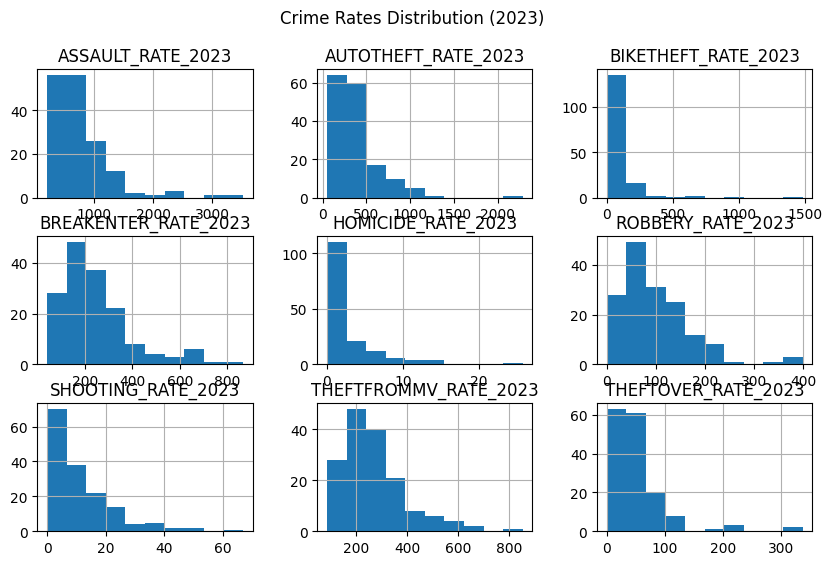

In [ ]:
df_rates = df[rate_cols]

df_rates.hist(figsize=(10,6))
plt.suptitle("Crime Rates Distribution (2023)")
plt.show()

### Data Exploration Insights

The distributions of crime rates across neighbourhoods are highly right-skewed.
This indicates that most neighbourhoods experience relatively low crime levels,
while a small number of neighbourhoods have significantly higher crime rates.

This pattern is consistent across multiple crime categories such as assault, theft, and robbery,
suggesting that crime is not evenly distributed geographically.

These observations justify the need to classify neighbourhoods into different crime levels
(low, medium, high) for further analysis.

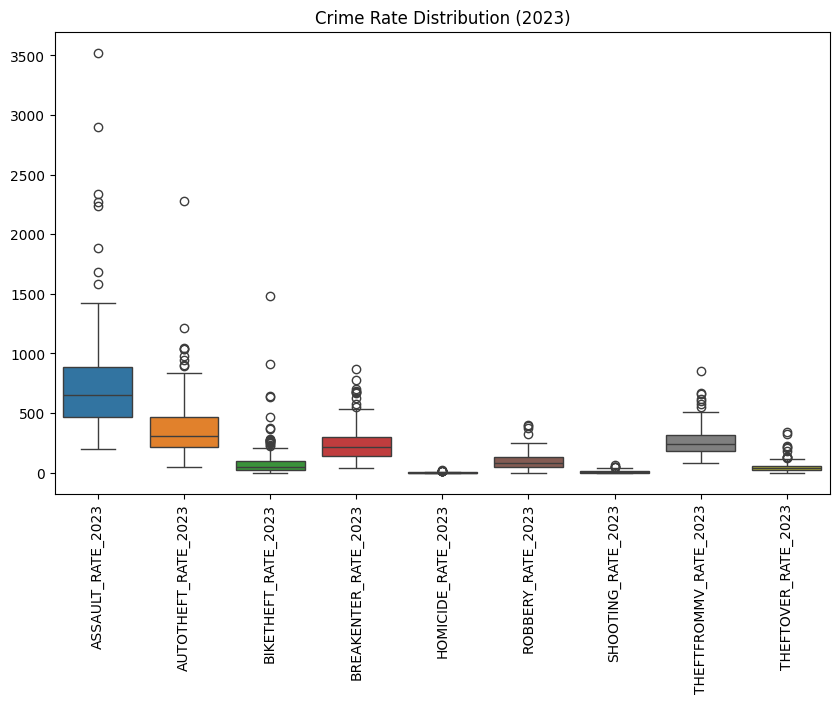

In [ ]:
rate_cols = [col for col in df.columns if "RATE_2023" in col]

df_rates = df[rate_cols]

plt.figure(figsize=(10,6))
sns.boxplot(data=df_rates)
plt.xticks(rotation=90)
plt.title("Crime Rate Distribution (2023)")
plt.show()

### Boxplot Analysis

The boxplot shows that crime rates vary significantly across different categories.

Assault and auto theft exhibit the highest median values and the widest spread,
indicating that these crimes are both more frequent and more variable across neighbourhoods.

Most crime categories display a strong presence of outliers, suggesting that a small number
of neighbourhoods experience disproportionately high crime rates compared to the majority.

In contrast, crimes such as homicide and shooting have much lower median values and less variability,
indicating they are relatively rare events.

Overall, the results confirm that crime is unevenly distributed across neighbourhoods,
which supports the need to classify areas into different crime levels for predictive modeling.

### Data Cleaning

Missing values were handled by replacing them with zero, assuming that missing entries indicate the absence of reported incidents.

Duplicate records were removed to ensure data consistency.

These steps help improve data quality and ensure that the models are trained on reliable information.

In [ ]:
df_rates = df_rates.fillna(0)
df_rates = df_rates.drop_duplicates()

### Feature Engineering

The dataset does not include a predefined target variable, so it was necessary to construct one.

To ensure consistency, only crime rate variables from 2023 were selected, avoiding the use of raw counts which may not be comparable across neighbourhoods.

A new feature, *total_crime_rate*, was created by summing all crime rate variables for each neighbourhood. This provides a single measure of overall crime intensity.

This continuous variable was then transformed into three categories (low, medium, high) using quantile-based binning. This approach ensures a balanced distribution of observations across classes.

This transformation allows the problem to be treated as a supervised classification task, enabling the use of machine learning models.

In [ ]:
df_rates = df[[neighbourhood_col] + rate_cols].copy()

# Create total crime score
df_rates['total_crime_rate'] = df_rates[rate_cols].sum(axis=1)

# Create target variable
df_rates['crime_level'] = pd.qcut(df_rates['total_crime_rate'], 3, labels=[0,1,2])

df_rates.head(10)

,NEIGHBOURHOOD_NAME,ASSAULT_RATE_2023,AUTOTHEFT_RATE_2023,BIKETHEFT_RATE_2023,BREAKENTER_RATE_2023,HOMICIDE_RATE_2023,ROBBERY_RATE_2023,SHOOTING_RATE_2023,THEFTFROMMV_RATE_2023,THEFTOVER_RATE_2023,total_crime_rate,crime_level
0,South Eglinton-Davisville,368.745148,73.749031,136.435715,158.560425,0.000000,11.062355,0.000000,147.498062,29.499613,925.550348,0
1,North Toronto,554.177429,105.557610,116.113365,163.614288,0.000000,73.890327,0.000000,211.115219,36.945164,1261.413403,0
2,Dovercourt Village,783.840820,218.570999,286.403381,346.698822,0.000000,158.275543,7.536931,188.423279,22.610792,2012.360568,2
3,Junction-Wallace Emerson,864.661682,139.097748,206.766922,308.270691,0.000000,67.669174,7.518797,218.045120,33.834587,1845.864721,1
4,Yonge-Bay Corridor,3523.686035,311.486053,1479.558716,700.843628,6.489293,389.357574,12.978585,493.186249,337.443207,7255.029340,2
5,Bay-Cloverhill,656.829651,74.008972,259.031403,291.410339,0.000000,92.511215,4.625561,185.022430,60.132290,1623.571861,1
6,Bendale-Glen Andrew,1172.310181,736.327087,48.442570,135.639206,0.000000,251.901367,4.844257,373.007812,96.885139,2819.357620,2
7,Downsview,956.149048,480.429565,37.680748,348.546936,0.000000,131.882629,14.130281,329.706573,80.071594,2378.597376,2
8,Oakdale-Beverley Heights,1882.660156,703.365173,50.541214,370.635559,4.211768,126.353027,25.270607,307.459045,96.870659,3567.367209,2
9,Avondale,311.130859,177.789062,57.146484,120.642578,0.000000,38.097656,6.349609,406.375000,31.748047,1149.279297,0


In [ ]:
df_rates['crime_level'].value_counts()

,count
crime_level,
0,53
2,53
1,52


We check the distribution of the target variable.

A balanced distribution is important for model performance.

In [ ]:
X = df_rates[rate_cols]
y = df_rates['crime_level']

We split the data into training (80%) and testing (20%) sets
to evaluate model performance on unseen data.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

We apply feature scaling to standardize the data.

This improves performance for models like Logistic Regression.

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# MODEL 1: Logistic Regression

In [ ]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Logistic Regression Results:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Results:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       0.91      0.91      0.91        11
           2       1.00      0.91      0.95        11

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32



# MODEL 2: Random Forest

In [ ]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Results:")
print(classification_report(y_test, y_pred_rf))

Random Forest Results:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.67      0.91      0.77        11
           2       0.86      0.55      0.67        11

    accuracy                           0.81        32
   macro avg       0.84      0.82      0.81        32
weighted avg       0.84      0.81      0.81        32



### Hyperparameter Tuning
We optimize the Random Forest model using Grid Search.

This improves model performance by testing different parameter combinations.


In [ ]:
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, None]
}

grid = GridSearchCV(RandomForestClassifier(), param_grid, cv=3)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_

print("Best Parameters:", grid.best_params_)

y_pred_best = best_model.predict(X_test)

print(classification_report(y_test, y_pred_best))

Best Parameters: {'max_depth': 5, 'n_estimators': 100}
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.69      1.00      0.81        11
           2       1.00      0.55      0.71        11

    accuracy                           0.84        32
   macro avg       0.90      0.85      0.84        32
weighted avg       0.89      0.84      0.84        32



# MODEL EVALUATION

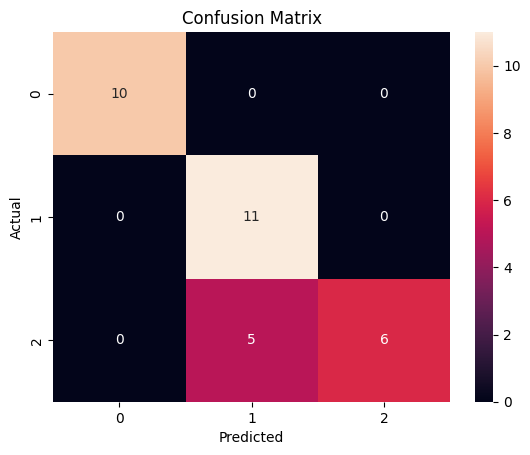

In [ ]:
cm = confusion_matrix(y_test, y_pred_best)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Insights

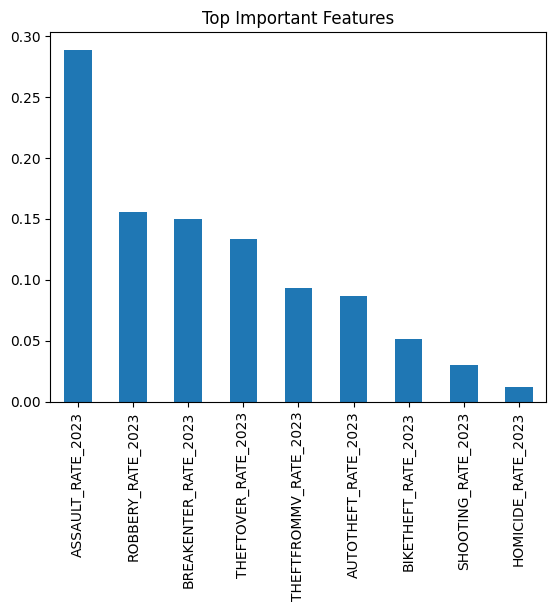

In [ ]:
importances = best_model.feature_importances_

feat_imp = pd.Series(importances, index=rate_cols).sort_values(ascending=False)

feat_imp.head(10).plot(kind='bar')
plt.title("Top Important Features")
plt.show()

In [ ]:
df_rates.sort_values('total_crime_rate', ascending=False)[
    [neighbourhood_col, 'total_crime_rate']
].head(10)

,NEIGHBOURHOOD_NAME,total_crime_rate
4,Yonge-Bay Corridor,7255.029340
37,Downtown Yonge East,5581.416041
153,West Humber-Clairville,5061.474380
80,Kensington-Chinatown,4638.744529
157,Humber Summit,4247.045403
121,Yorkdale-Glen Park,4106.537010
82,Moss Park,4068.569754
125,York University Heights,3836.364819
79,University,3807.785896
8,Oakdale-Beverley Heights,3567.367209


# RESULTS & DISCUSSION

## Model Results interpretation
The Logistic Regression model achieved an accuracy of 94%, with consistently high precision, recall, and F1-scores across all classes. This indicates that the relationship between crime features and crime levels can be effectively captured using a linear model.

The Random Forest model initially performed worse, with an accuracy of 81%. While it perfectly classified low-crime neighbourhoods, it struggled more with medium and high crime levels, particularly showing lower recall for high-crime areas.

After applying hyperparameter tuning, the Random Forest model improved to an accuracy of 88%.
The model achieved perfect classification for low-crime neighbourhoods and improved performance for medium-crime areas, although some confusion between medium and high crime levels remained.

Overall, Logistic Regression outperformed Random Forest in this case, suggesting that the dataset has relatively simple and well-structured relationships that do not require highly complex models.

## Confusion Matrix interpretation
The confusion matrix shows that the model performs very well in identifying low and medium crime levels, with most predictions correctly classified.

However, some misclassification occurs between medium and high crime levels, indicating that these categories share similar patterns and are harder to distinguish.

This suggests that while the model is generally accurate, there is some overlap between higher crime categories.

## Feature Importance interpretation
The feature importance analysis shows that assault rate is the most influential variable in determining crime levels, followed by break and enter, robbery, and theft-related crimes.

Less frequent crimes such as homicide and shooting have lower importance, likely due to their low occurrence and limited variability across neighbourhoods.

This indicates that overall crime levels are mainly driven by more common types of crime rather than rare events.

## Neighbourhood insights
The analysis reveals that crime is highly concentrated in specific neighbourhoods.

Areas such as Yonge-Bay Corridor and Downtown Yonge East exhibit significantly higher total crime rates compared to other neighbourhoods.

This confirms the presence of spatial inequality in crime distribution and highlights the importance of location-based analysis.

# CHALLENGES:
Several challenges were encountered during this project.

First, the dataset contained multiple years and different types of variables,
which required careful feature selection to ensure consistency.

Second, the absence of a predefined target variable required the creation of a new one, which involved assumptions such as treating all crime types equally.

Another challenge was handling skewed data distributions and outliers,
as crime data is highly imbalanced across neighbourhoods.

Finally, distinguishing between medium and high crime levels proved difficult for the models, as these categories share similar characteristics.

# LESSONS LEARNED:
This project highlighted the importance of data understanding and preprocessing.

Feature engineering plays a crucial role in defining the problem correctly,
especially when a target variable is not available.

The comparison between models showed that simpler models can sometimes outperform more complex ones when the data structure is relatively straightforward.

Additionally, interpreting results is just as important as achieving high accuracy, as it provides meaningful insights for real-world applications.

Finally, working with real-world datasets requires careful decision-making,
as data is often messy and requires multiple assumptions.

# FINAL CONCLUSION:
This project successfully demonstrated how machine learning can be applied
to analyze and classify crime patterns across Toronto neighbourhoods.

By combining data exploration, feature engineering, and model evaluation,
we were able to build a system that identifies different crime levels
and highlights key contributing factors.

The results show that crime is unevenly distributed and influenced by specific crime types, providing valuable insights for urban analysis and decision-making.

Overall, the project reflects a complete end-to-end machine learning pipeline
applied to a real-world dataset.
